# 01 · Toy check: does the round map predict FedAvg's divergence exactly?

In [2]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))   # repo root when run from notebooks/
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from eosfl import obs
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
def edge_line(ax, y=1.0):
    ax.axhline(y, color="k", lw=0.8)

In [3]:
toy = obs.load_toy()
toy.head()

,het,server_lr,K,lam_glob,lam_client_max,lr_pred,lr_emp,rel_err,glob_norm,client_norm,glob_norm_slr
0,0.0,0.5,1,10.0,10.0,0.402,0.402,0.000,2.008,2.008,1.004
1,0.0,0.5,2,10.0,10.0,0.200,0.202,0.005,1.002,1.002,0.501
2,0.0,0.5,3,10.0,10.0,0.245,0.245,0.000,1.226,1.226,0.613
3,0.0,0.5,5,10.0,10.0,0.225,0.225,0.000,1.127,1.127,0.563
4,0.0,0.5,10,10.0,10.0,0.200,0.200,0.000,1.002,1.002,0.501


## 1. Prediction vs simulation

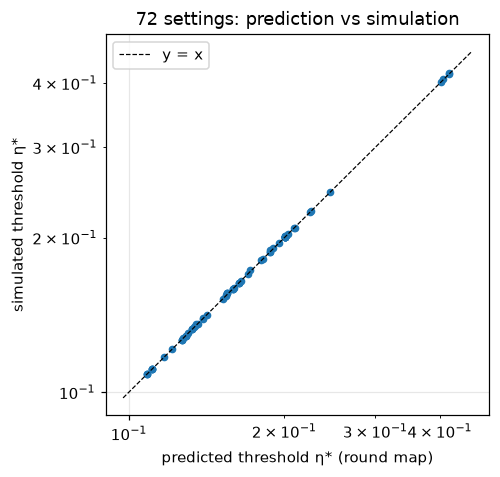

max relative error over 72 settings: 0.0060  (one step of the η grid is ≈0.6%)


In [4]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.loglog(toy.lr_pred, toy.lr_emp, "o", ms=4)
lims = [toy[["lr_pred", "lr_emp"]].min().min() * 0.9, toy[["lr_pred", "lr_emp"]].max().max() * 1.1]
ax.plot(lims, lims, "k--", lw=0.8, label="y = x")
ax.set_xlabel("predicted threshold η* (round map)"); ax.set_ylabel("simulated threshold η*"); ax.legend()
ax.set_title("72 settings: prediction vs simulation")
plt.show()
print(f"max relative error over {len(toy)} settings: {toy.rel_err.max():.4f}  (one step of the η grid is ≈0.6%)")

## 2. Where is the edge? (η_s = 1)

`glob_norm` = global sharpness at the edge, `client_norm` = sharpest client at the edge.

In [5]:
s1 = toy[toy.server_lr == 1.0]
display(s1.pivot(index="het", columns="K", values="glob_norm").round(3).rename_axis("global ·η/2  (het \\ K)"))
display(s1.pivot(index="het", columns="K", values="client_norm").round(3).rename_axis("max client ·η/2  (het \\ K)"))

K,1,2,3,5,10,20
global ·η/2 (het \ K),,,,,,
0.0,1.002,1.002,1.002,1.002,1.002,1.002
0.3,1.003,0.927,0.897,0.848,0.807,0.785
0.6,1.005,0.748,0.743,0.681,0.639,0.621
0.9,1.005,0.608,0.645,0.583,0.533,0.520


K,1,2,3,5,10,20
max client ·η/2 (het \ K),,,,,,
0.0,1.002,1.002,1.002,1.002,1.002,1.002
0.3,1.320,1.221,1.181,1.117,1.062,1.033
0.6,1.670,1.242,1.234,1.131,1.061,1.031
0.9,1.988,1.203,1.277,1.153,1.054,1.029


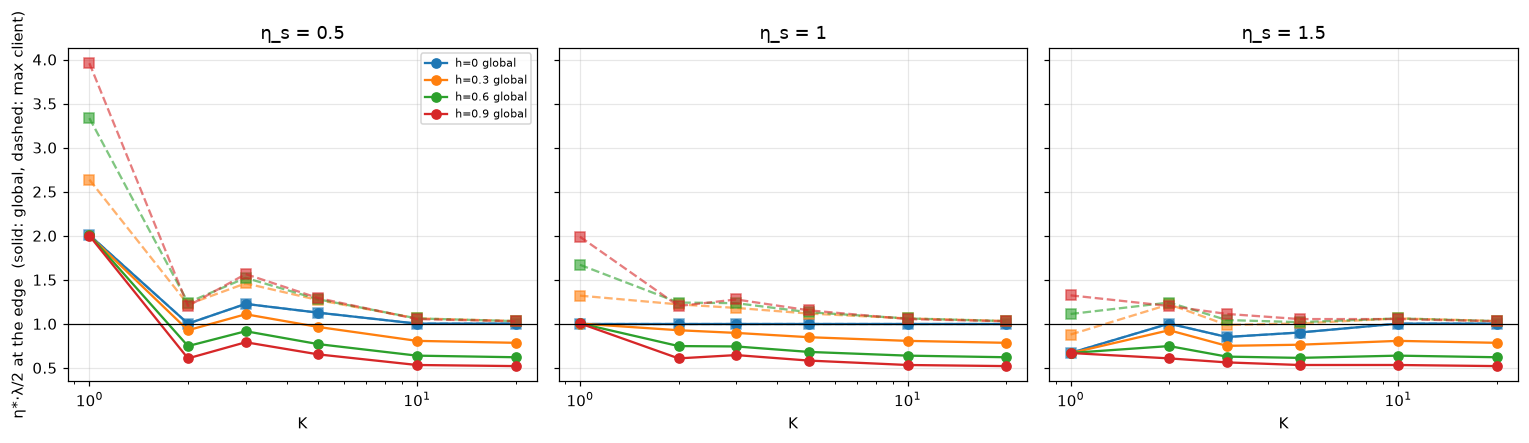

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, slr in zip(axes, sorted(toy.server_lr.unique())):
    for het, g in toy[toy.server_lr == slr].groupby("het"):
        line, = ax.plot(g.K, g.glob_norm, "o-", label=f"h={het:g} global")
        ax.plot(g.K, g.client_norm, "s--", color=line.get_color(), alpha=0.6)
    edge_line(ax); ax.set_xscale("log"); ax.set_xlabel("K"); ax.set_title(f"η_s = {slr:g}")
axes[0].set_ylabel("η*·λ/2 at the edge  (solid: global, dashed: max client)"); axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Server step and parity

For identical clients each round-map eigenvalue is `1 − η_s(1 − a)` with `a = (1 − ηλ)ᴷ`. Stability needs `1 − 2/η_s < a < 1`.

- Even K: `a ≥ 0`, so only `a > 1` can break it, i.e. `ηλ > 2`. Edge exactly 2/η for every η_s.
- Odd K: `a` can be negative; instability at `a = 1 − 2/η_s`. Solving gives the edge `ηλ/2 = (1 + |1 − 2/η_s|^{1/K})/2` when η_s < 1 and `(1 + (2/η_s − 1)^{1/K})/2` when η_s > 1.

In [7]:
def analytic(K, slr):
    if K % 2 == 0 or slr == 1:
        return 1.0 if K > 1 or slr == 1 else 1 / slr
    if K == 1:
        return 1 / slr
    return (1 + abs(1 - 2 / slr) ** (1 / K)) / 2
h0 = toy[toy.het == 0].copy()
h0["analytic"] = [analytic(k, s) for k, s in zip(h0.K, h0.server_lr)]
display(h0.pivot(index="server_lr", columns="K", values="glob_norm").round(3).rename_axis("toy, h=0"))
display(h0.pivot(index="server_lr", columns="K", values="analytic").round(3).rename_axis("closed form"))
print("max |toy − closed form|:", (h0.glob_norm - h0.analytic).abs().max().round(4))

K,1,2,3,5,10,20
"toy, h=0",,,,,,
0.5,2.008,1.002,1.226,1.127,1.002,1.002
1.0,1.002,1.002,1.002,1.002,1.002,1.002
1.5,0.670,1.002,0.850,0.902,1.002,1.002


K,1,2,3,5,10,20
closed form,,,,,,
0.5,2.000,1.0,1.221,1.123,1.0,1.0
1.0,1.000,1.0,1.000,1.000,1.0,1.0
1.5,0.667,1.0,0.847,0.901,1.0,1.0


max |toy − closed form|: 0.0082


## Conclusions

1. **The round map is exact on quadratics.** Predicted and simulated thresholds agree to one grid step (section 1).
2. **H2 holds here:** identical clients, η_s = 1 → edge at 2/η for every K (row h = 0 of the first table).
3. **H3 holds here, as a mechanism:** with heterogeneous clients the global value at the edge falls below 1 and falls more with h, while the sharpest client approaches 1 as K grows. The binding constraint moves from the global loss (K = 1) to the sharpest client (large K). The K effect is gradual up to about K = 10.
4. **H4 holds, with parity:** at K = 1 the edge is 2/(η·η_s); for K > 1 even K returns to 2/η exactly, odd K is shifted by a closed-form amount (section 3).

**Limit:** quadratics cannot self-stabilize. Real networks can (notebooks 02–05), which is where the toy picture breaks quantitatively.